In [1]:
import os
import sys
import h5py
import numpy
from matplotlib import colors
from matplotlib import pyplot
from matplotlib import colorbar
from sklearn.model_selection import train_test_split

In [2]:
import tensorflow
import tensorflow_probability
from tensorflow_probability import stats
from tensorflow import math, keras, linalg

In [3]:
from keras.utils import plot_model
from keras.initializers import HeNormal
from keras import layers, losses, Model, Sequential
from keras.regularizers import OrthogonalRegularizer
from keras.layers import Layer, Flatten, Reshape, Dense, LeakyReLU, Conv1D, Conv1DTranspose, Dropout, BatchNormalization

In [4]:
BIN_SIZE = 5
GRID_SIZE = 300
LATENT_SIZE = 8
MOCK_SIZE = 100000
DATA_SIZE = (GRID_SIZE, BIN_SIZE)

Z1 = 0.0
Z2 = 3.0
Z_DELTA = (Z2 - Z1) / GRID_SIZE
Z_EDGE = numpy.linspace(Z1, Z2, GRID_SIZE + 1)
Z_GRID = numpy.linspace(Z1 + Z_DELTA / 2, Z2 - Z_DELTA / 2, GRID_SIZE)

PHI0 = 6.0
PHI1 = 0.0
PHI2 = 5.0

In [5]:
LABEL = 'SOURCE'
PATH = '/pscratch/sd/y/yhzhang/VAECloud/'

DATA_PATH = os.path.join(PATH, 'DATA/{}/'.format(LABEL))
PLOT_PATH = os.path.join(PATH, 'PLOT/{}/VAE/'.format(LABEL))

with h5py.File(DATA_PATH + 'INPUT.hdf5','r') as FILE:
    COUNT = FILE['count'][:].astype('float32')
    INPUT = FILE['data'][:].astype('float32')

FACTOR = COUNT * Z_DELTA
INPUT = INPUT / FACTOR[:, :, numpy.newaxis]

In [6]:
INPUT_DATA = numpy.transpose(INPUT, axes = (0, 2, 1)) / PHI0
TRAIN_DATA, EVALUATION_DATA = train_test_split(INPUT_DATA, test_size = 0.2)
VALIDATION_DATA, TEST_DATA = train_test_split(EVALUATION_DATA, test_size = 0.5)

In [7]:
class Encoder(Layer):

    def __init__(self, delta, scale, latent_size):

        super(Encoder, self).__init__()

        self.delta = delta
        self.scale = scale
        self.encoder = Sequential()

        self.encoder.add(Conv1D(filters = 128, kernel_size = 3, strides = 2, padding = 'same', kernel_initializer = HeNormal()))
        self.encoder.add(BatchNormalization())
        self.encoder.add(Dropout(0.25))
        self.encoder.add(LeakyReLU())

        self.encoder.add(Conv1D(filters = 256, kernel_size = 3, strides = 2, padding = 'same', kernel_initializer = HeNormal()))
        self.encoder.add(BatchNormalization())
        self.encoder.add(Dropout(0.25))
        self.encoder.add(LeakyReLU())

        self.encoder.add(Conv1D(filters = 512, kernel_size = 3, strides = 3, padding = 'same', kernel_initializer = HeNormal()))
        self.encoder.add(BatchNormalization())
        self.encoder.add(Dropout(0.25))
        self.encoder.add(LeakyReLU())

        self.encoder.add(Conv1D(filters = 1024, kernel_size = 3, strides = 5, padding = 'same', kernel_initializer = HeNormal()))
        self.encoder.add(BatchNormalization())
        self.encoder.add(Dropout(0.25))
        self.encoder.add(LeakyReLU())
        
        self.encoder.add(Flatten())
        
        self.mu = Dense(units = latent_size, kernel_initializer = HeNormal(), kernel_regularizer = OrthogonalRegularizer(factor = 0.001))
        self.logvar = Dense(units = latent_size, kernel_initializer = HeNormal(), kernel_regularizer = OrthogonalRegularizer(factor = 0.001))

    def call(self, input_data):

        latent_data = input_data / math.reduce_sum(input_data, axis = 1, keepdims = True) / self.delta / self.scale
        latent_data = self.encoder(latent_data)

        latent_mu = self.mu(latent_data)
        latent_logvar = self.logvar(latent_data)

        return latent_mu, latent_logvar

In [8]:
class Decoder(Layer):

    def __init__(self, delta, scale, data_size, latent_size):

        super(Decoder, self).__init__()

        grid_size, bin_size = data_size
        self.decoder = Sequential()
        self.delta = delta
        self.scale = scale

        self.decoder.add(Dense(units = grid_size // 60 * 1024, kernel_initializer = HeNormal(), kernel_regularizer = OrthogonalRegularizer(factor = 0.001)))
        self.decoder.add(BatchNormalization())
        self.decoder.add(Dropout(0.25))
        self.decoder.add(LeakyReLU())
        
        self.decoder.add(Reshape((grid_size // 60, 1024)))
        
        self.decoder.add(Conv1DTranspose(filters = 512, kernel_size = 3, strides = 5, padding = 'same', kernel_initializer = HeNormal()))
        self.decoder.add(BatchNormalization())
        self.decoder.add(Dropout(0.25))
        self.decoder.add(LeakyReLU())

        self.decoder.add(Conv1DTranspose(filters = 256, kernel_size = 3, strides = 3, padding = 'same', kernel_initializer = HeNormal()))
        self.decoder.add(BatchNormalization())
        self.decoder.add(Dropout(0.25))
        self.decoder.add(LeakyReLU())

        self.decoder.add(Conv1DTranspose(filters = 128, kernel_size = 3, strides = 2, padding = 'same', output_padding = 1, kernel_initializer = HeNormal()))
        self.decoder.add(BatchNormalization())
        self.decoder.add(Dropout(0.25))
        self.decoder.add(LeakyReLU())

        self.decoder.add(Conv1DTranspose(filters = bin_size, kernel_size = 3, strides = 2, padding = 'same', activation = 'softplus', kernel_initializer = HeNormal()))

    def call(self, latent_data):

        output_data = self.decoder(latent_data)
        output_data = output_data / math.reduce_sum(output_data, axis = 1, keepdims = True) / self.delta / self.scale

        return output_data

In [9]:
class VAE(Model):

    def __init__(self, delta, scale, data_size, latent_size):

        super(VAE, self).__init__()

        self.encoder = Encoder(delta, scale, latent_size)
        self.decoder = Decoder(delta, scale, data_size, latent_size)
        
        self.all_loss_tracker = keras.metrics.Mean(name = 'all_loss')
        self.mean_loss_tracker = keras.metrics.Mean(name = 'mean_loss')
        self.scatter_loss_tracker = keras.metrics.Mean(name = 'scatter_loss')
        self.covariance_loss_tracker = keras.metrics.Mean(name = 'covariance_loss')
        self.divergence_loss_tracker = keras.metrics.Mean(name = 'divergence_loss')

    def call(self, input_data):
        latent_mu, latent_logvar = self.encoder(input_data)
        latent_data = self.sampler(latent_mu, latent_logvar)
        output_data = self.decoder(latent_data)
        return output_data

    @property
    def metrics(self):
        return [self.all_loss_tracker, self.mean_loss_tracker, self.scatter_loss_tracker, self.covariance_loss_tracker, self.divergence_loss_tracker]
    
    def mean_loss(self, input_data, output_data):
        
        input_mean = math.reduce_mean(input_data, axis = 0)
        output_mean = math.reduce_mean(output_data, axis = 0)
        return math.reduce_mean(losses.huber(input_mean, output_mean, 0.001))
    
    def scatter_loss(self, input_data, output_data):
        
        input_scatter = math.reduce_std(input_data, axis = 0)
        output_scatter = math.reduce_std(output_data, axis = 0)
        return math.reduce_mean(losses.huber(input_scatter, output_scatter, 0.005))
    
    def covariance_loss(self, input_data, output_data):
        
        input_covariance = stats.covariance(input_data, sample_axis = 0, event_axis = (1, 2))
        output_covariance = stats.covariance(output_data, sample_axis = 0, event_axis = (1, 2))
        return math.reduce_mean(losses.mean_absolute_error(input_covariance, output_covariance))
     
    def divergence_loss(self, latent_mu, latent_logvar):
                  
        return math.reduce_mean(- 0.5 * (1 + latent_logvar - math.square(latent_mu) - math.exp(latent_logvar)))

    def sampler(self, mu, logvar):

        epsilon = tensorflow.random.normal(shape = tensorflow.shape(mu))
        return mu + epsilon * math.exp(logvar * 0.5)
    
    def train_step(self, input_data):

        with tensorflow.GradientTape() as tape:

            latent_mu, latent_logvar = self.encoder(input_data)
            latent_data = self.sampler(latent_mu, latent_logvar)
            output_data = self.decoder(latent_data)         
            
            mean_loss = self.mean_loss(input_data, output_data)
            scatter_loss = self.scatter_loss(input_data, output_data)
            covariance_loss = self.covariance_loss(input_data, output_data)
            divergence_loss = self.divergence_loss(latent_mu, latent_logvar)
            all_loss = mean_loss + scatter_loss + covariance_loss + divergence_loss

            gradients = tape.gradient(all_loss, self.trainable_weights)
            self.optimizer.apply_gradients(zip(gradients, self.trainable_weights))
            
            self.all_loss_tracker.update_state(all_loss)
            self.mean_loss_tracker.update_state(mean_loss)
            self.scatter_loss_tracker.update_state(scatter_loss)
            self.covariance_loss_tracker.update_state(covariance_loss)
            self.divergence_loss_tracker.update_state(divergence_loss)

        return {'all_loss': self.all_loss_tracker.result(), 'mean_loss': self.mean_loss_tracker.result(), 'scatter_loss': self.scatter_loss_tracker.result(), 'covariance_loss': self.covariance_loss_tracker.result(), 'divergence_loss': self.divergence_loss_tracker.result()}

    def test_step(self, test_data):

        input_data, evaluation_data = test_data

        latent_mu, latent_logvar = self.encoder(input_data)
        latent_data = self.sampler(latent_mu, latent_logvar)
        output_data = self.decoder(latent_data)

        mean_loss = self.mean_loss(input_data, output_data)
        scatter_loss = self.scatter_loss(input_data, output_data)
        covariance_loss = self.covariance_loss(input_data, output_data)
        divergence_loss = self.divergence_loss(latent_mu, latent_logvar)
        all_loss = mean_loss + scatter_loss + covariance_loss + divergence_loss
        
        self.all_loss_tracker.update_state(all_loss)
        self.mean_loss_tracker.update_state(mean_loss)
        self.scatter_loss_tracker.update_state(scatter_loss)
        self.covariance_loss_tracker.update_state(covariance_loss)
        self.divergence_loss_tracker.update_state(divergence_loss)

        return {'all_loss': self.all_loss_tracker.result(), 'mean_loss': self.mean_loss_tracker.result(), 'scatter_loss': self.scatter_loss_tracker.result(), 'covariance_loss': self.covariance_loss_tracker.result(), 'divergence_loss': self.divergence_loss_tracker.result()}

In [10]:
RATE = 0.0001
EPOCH_SIZE = 32
BATCH_SIZE = 256

DEVICES = tensorflow.config.experimental.list_physical_devices('GPU')
for DEVICE in DEVICES:
    tensorflow.config.experimental.set_memory_growth(DEVICE, True)
    
STRAREGY = tensorflow.distribute.MirroredStrategy()
with STRAREGY.scope():
    MODEL = VAE(Z_DELTA, PHI0, DATA_SIZE, LATENT_SIZE)
    MODEL.compile(optimizer = keras.optimizers.Adam(learning_rate = RATE, clipvalue = 1.0))

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1', '/job:localhost/replica:0/task:0/device:GPU:2', '/job:localhost/replica:0/task:0/device:GPU:3')
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task

2024-07-08 19:22:48.684368: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-07-08 19:22:50.519668: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1532] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 78933 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:03:00.0, compute capability: 8.0
2024-07-08 19:22:50.521273: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1532] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 78933 MB memory:  -> device: 1, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:41:00.0, compute capability: 8.0
2024-07-08 19:22:50.522620: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1532] Created device /job:localhost/replica:0/task:0/devi

In [11]:
HISTORY = MODEL.fit(TRAIN_DATA, shuffle = True, verbose = 'auto', epochs = EPOCH_SIZE, validation_data = [VALIDATION_DATA, VALIDATION_DATA])
LATENT_MU, LATENT_LOGVAR = MODEL.encoder(TEST_DATA)
LATENT_DATA = MODEL.sampler(LATENT_MU, LATENT_LOGVAR)

2024-07-08 19:22:51.209660: W tensorflow/core/grappler/optimizers/data/auto_shard.cc:776] AUTO sharding policy will apply DATA sharding policy as it failed to apply FILE sharding policy because of the following reason: Did not find a shardable source, walked to a node which is not a dataset: name: "FlatMapDataset/_9"
op: "FlatMapDataset"
input: "PrefetchDataset/_8"
attr {
  key: "Targuments"
  value {
    list {
    }
  }
}
attr {
  key: "_cardinality"
  value {
    i: -2
  }
}
attr {
  key: "f"
  value {
    func {
      name: "__inference_Dataset_flat_map_slice_batch_indices_539"
    }
  }
}
attr {
  key: "metadata"
  value {
    s: "\n\020FlatMapDataset:4"
  }
}
attr {
  key: "output_shapes"
  value {
    list {
      shape {
        dim {
          size: 32
        }
      }
    }
  }
}
attr {
  key: "output_types"
  value {
    list {
      type: DT_INT64
    }
  }
}
experimental_type {
  type_id: TFT_PRODUCT
  args {
    type_id: TFT_DATASET
    args {
      type_id: TFT_PRODUCT


Epoch 1/32
INFO:tensorflow:batch_all_reduce: 38 all-reduces with algorithm = nccl, num_packs = 1
INFO:tensorflow:batch_all_reduce: 38 all-reduces with algorithm = nccl, num_packs = 1


2024-07-08 19:23:00.631515: I tensorflow/stream_executor/cuda/cuda_blas.cc:1786] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.
2024-07-08 19:23:00.765593: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8302
2024-07-08 19:23:01.561834: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8302
2024-07-08 19:23:02.414019: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8302
2024-07-08 19:23:03.230107: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8302


2497/2500 [============================>.] - ETA: 0s - all_loss: 3.8556e-04 - mean_loss: 6.6415e-05 - scatter_loss: 4.9078e-05 - covariance_loss: 1.8753e-04 - divergence_loss: 8.2541e-05

2024-07-08 19:23:26.369194: W tensorflow/core/grappler/optimizers/data/auto_shard.cc:776] AUTO sharding policy will apply DATA sharding policy as it failed to apply FILE sharding policy because of the following reason: Did not find a shardable source, walked to a node which is not a dataset: name: "FlatMapDataset/_9"
op: "FlatMapDataset"
input: "PrefetchDataset/_8"
attr {
  key: "Targuments"
  value {
    list {
    }
  }
}
attr {
  key: "_cardinality"
  value {
    i: -2
  }
}
attr {
  key: "f"
  value {
    func {
      name: "__inference_Dataset_flat_map_slice_batch_indices_36679"
    }
  }
}
attr {
  key: "metadata"
  value {
    s: "\n\021FlatMapDataset:36"
  }
}
attr {
  key: "output_shapes"
  value {
    list {
      shape {
        dim {
          size: -1
        }
      }
    }
  }
}
attr {
  key: "output_types"
  value {
    list {
      type: DT_INT64
    }
  }
}
experimental_type {
  type_id: TFT_PRODUCT
  args {
    type_id: TFT_DATASET
    args {
      type_id: TFT_PRODU

2500/2500 [==============================] - 40s 10ms/step - all_loss: 3.8547e-04 - mean_loss: 6.6384e-05 - scatter_loss: 4.9071e-05 - covariance_loss: 1.8753e-04 - divergence_loss: 8.2483e-05 - val_all_loss: 2.9541e-04 - val_mean_loss: 4.1131e-05 - val_scatter_loss: 3.9125e-05 - val_covariance_loss: 1.7395e-04 - val_divergence_loss: 4.1199e-05
Epoch 2/32
2500/2500 [==============================] - 22s 9ms/step - all_loss: 2.6228e-04 - mean_loss: 3.1687e-05 - scatter_loss: 3.8616e-05 - covariance_loss: 1.7496e-04 - divergence_loss: 1.7018e-05 - val_all_loss: 2.4501e-04 - val_mean_loss: 2.9150e-05 - val_scatter_loss: 3.7827e-05 - val_covariance_loss: 1.7018e-04 - val_divergence_loss: 7.8577e-06
Epoch 3/32
2500/2500 [==============================] - 22s 9ms/step - all_loss: 2.4845e-04 - mean_loss: 2.8751e-05 - scatter_loss: 3.8022e-05 - covariance_loss: 1.7300e-04 - divergence_loss: 8.6845e-06 - val_all_loss: 2.4148e-04 - val_mean_loss: 2.8510e-05 - val_scatter_loss: 3.7325e-05 - val_c

In [12]:
TEST_SIZE = int(MOCK_SIZE * 0.5 * 0.2)
TEST_INPUT = numpy.transpose(TEST_DATA, axes = (0, 2, 1)) * PHI0
TEST_OUTPUT = numpy.transpose(MODEL.predict(TEST_DATA), axes = (0, 2, 1)) * PHI0

2024-07-08 19:34:54.730240: W tensorflow/core/grappler/optimizers/data/auto_shard.cc:776] AUTO sharding policy will apply DATA sharding policy as it failed to apply FILE sharding policy because of the following reason: Did not find a shardable source, walked to a node which is not a dataset: name: "FlatMapDataset/_9"
op: "FlatMapDataset"
input: "PrefetchDataset/_8"
attr {
  key: "Targuments"
  value {
    list {
    }
  }
}
attr {
  key: "_cardinality"
  value {
    i: -2
  }
}
attr {
  key: "f"
  value {
    func {
      name: "__inference_Dataset_flat_map_slice_batch_indices_752834"
    }
  }
}
attr {
  key: "metadata"
  value {
    s: "\n\022FlatMapDataset:626"
  }
}
attr {
  key: "output_shapes"
  value {
    list {
      shape {
        dim {
          size: -1
        }
      }
    }
  }
}
attr {
  key: "output_types"
  value {
    list {
      type: DT_INT64
    }
  }
}
experimental_type {
  type_id: TFT_PRODUCT
  args {
    type_id: TFT_DATASET
    args {
      type_id: TFT_PRO

313/313 [==============================] - 3s 3ms/step


In [13]:
MODEL.save(DATA_PATH + 'MODEL')
numpy.savetxt(DATA_PATH + 'TEST_INPUT.txt', TEST_INPUT.reshape(TEST_SIZE, BIN_SIZE * GRID_SIZE))
numpy.savetxt(DATA_PATH + 'TEST_OUTPUT.txt', TEST_OUTPUT.reshape(TEST_SIZE, BIN_SIZE * GRID_SIZE))

INFO:tensorflow:Assets written to: /pscratch/sd/y/yhzhang/VAECloud/DATA/SOURCE/MODEL/assets


INFO:tensorflow:Assets written to: /pscratch/sd/y/yhzhang/VAECloud/DATA/SOURCE/MODEL/assets


In [14]:
%env PATH=/global/homes/y/yhzhang/opt/texlive/bin/x86_64-linux:$PATH

pyplot.rcParams['font.size'] = 25
pyplot.rcParams['text.usetex'] = True
pyplot.rcParams['pgf.texsystem'] = 'pdflatex'
pyplot.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
COLOR = ['darkviolet', 'darkblue', 'darkgreen', 'darkorange', 'darkred']

env: PATH=/global/homes/y/yhzhang/opt/texlive/bin/x86_64-linux:/pscratch/sd/y/yhzhang/VAECloud/


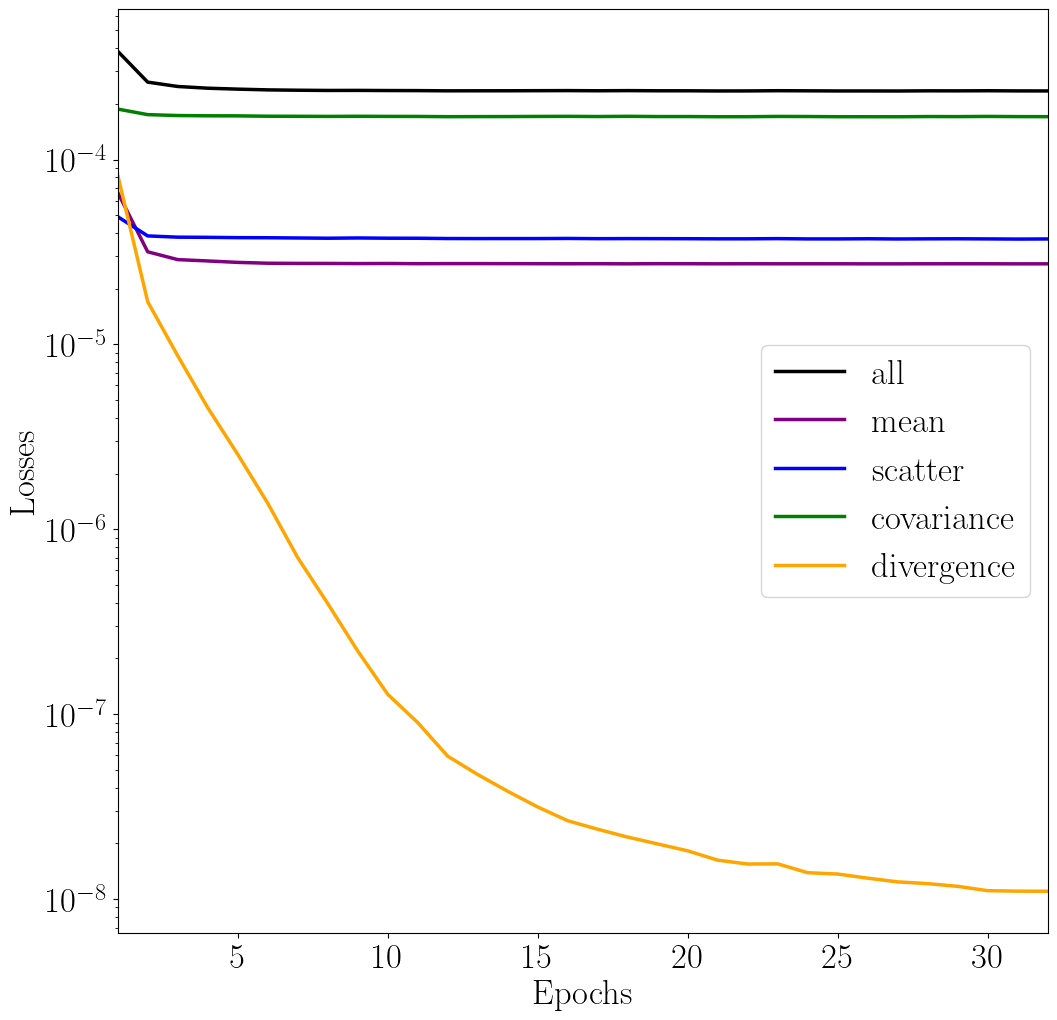

In [15]:
FIGURE, PLOT = pyplot.subplots(nrows = 1, ncols = 1, figsize = (12, 12))

EPOCH = numpy.arange(EPOCH_SIZE, dtype = 'int') + 1

PLOT.plot(EPOCH, HISTORY.history['all_loss'], color = 'black', linestyle = '-', linewidth = 2.5, label = r'$\mathrm{all}$')

PLOT.plot(EPOCH, HISTORY.history['mean_loss'], color = 'purple', linestyle = '-', linewidth = 2.5, label = r'$\mathrm{mean}$')

PLOT.plot(EPOCH, HISTORY.history['scatter_loss'], color = 'blue', linestyle = '-', linewidth = 2.5, label = r'$\mathrm{scatter}$')

PLOT.plot(EPOCH, HISTORY.history['covariance_loss'], color = 'green', linestyle = '-', linewidth = 2.5, label = r'$\mathrm{covariance}$')

PLOT.plot(EPOCH, HISTORY.history['divergence_loss'], color = 'orange', linestyle = '-', linewidth = 2.5, label = r'$\mathrm{divergence}$')

PLOT.set_yscale('log')
PLOT.set_xlim(1, EPOCH_SIZE)

PLOT.legend()
PLOT.set_xlabel(r'$\mathrm{Epochs}$')
PLOT.set_ylabel(r'$\mathrm{Losses}$')

FIGURE.savefig(PLOT_PATH + 'LOSS.pdf', bbox_inches = 'tight')

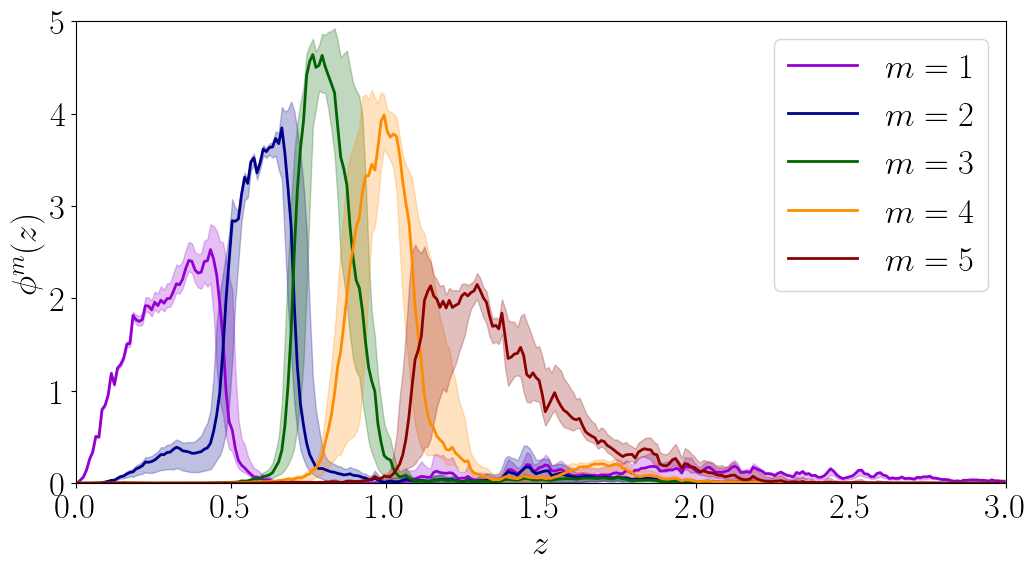

In [16]:
FIGURE, PLOT = pyplot.subplots(nrows = 1, ncols = 1, figsize = (12, 6))

for m in range(BIN_SIZE):
    
    PHI_QUANTILE0 = numpy.quantile(TEST_INPUT[:, m, :], q=0.50, axis=0)
    PHI_QUANTILE1 = numpy.quantile(TEST_INPUT[:, m, :], q=0.16, axis=0)
    PHI_QUANTILE2 = numpy.quantile(TEST_INPUT[:, m, :], q=0.84, axis=0)
    
    PLOT.plot(Z_GRID, PHI_QUANTILE0, color = COLOR[m], linewidth = 2.0, label = r'$m = {:.0f}$'.format(m + 1))

    PLOT.fill_between(Z_GRID, PHI_QUANTILE1, PHI_QUANTILE2, color = COLOR[m], alpha = 0.25)

PLOT.legend()
PLOT.set_xlim(Z1, Z2)
PLOT.set_ylim(PHI1, PHI2)

PLOT.set_xlabel(r'$z$')
PLOT.set_ylabel(r'$\phi^m (z)$')

FIGURE.savefig(PLOT_PATH + 'INPUT_DATA.pdf', bbox_inches = 'tight')

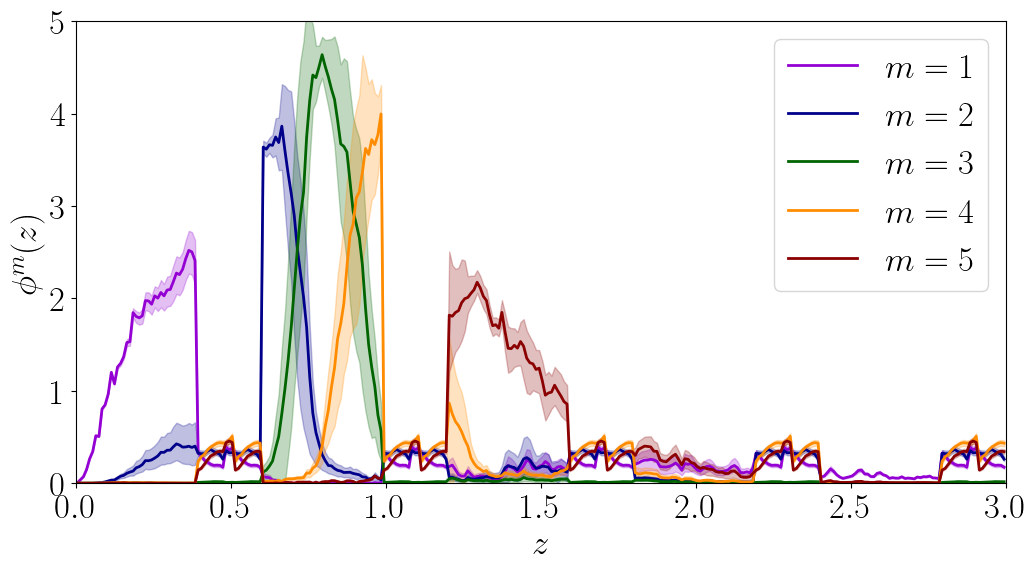

In [17]:
FIGURE, PLOT = pyplot.subplots(nrows = 1, ncols = 1, figsize = (12, 6))

for m in range(BIN_SIZE):
    
    PHI_QUANTILE0 = numpy.quantile(TEST_OUTPUT[:, m, :], q=0.50, axis=0)
    PHI_QUANTILE1 = numpy.quantile(TEST_OUTPUT[:, m, :], q=0.16, axis=0)
    PHI_QUANTILE2 = numpy.quantile(TEST_OUTPUT[:, m, :], q=0.84, axis=0)
    
    PLOT.plot(Z_GRID, PHI_QUANTILE0, color = COLOR[m], linewidth = 2.0, label = r'$m = {:.0f}$'.format(m + 1))

    PLOT.fill_between(Z_GRID, PHI_QUANTILE1, PHI_QUANTILE2, color = COLOR[m], alpha = 0.25)

PLOT.legend()
PLOT.set_xlim(Z1, Z2)
PLOT.set_ylim(PHI1, PHI2)

PLOT.set_xlabel(r'$z$')
PLOT.set_ylabel(r'$\phi^m (z)$')

FIGURE.savefig(PLOT_PATH + 'OUTPUT_DATA.pdf', bbox_inches = 'tight')

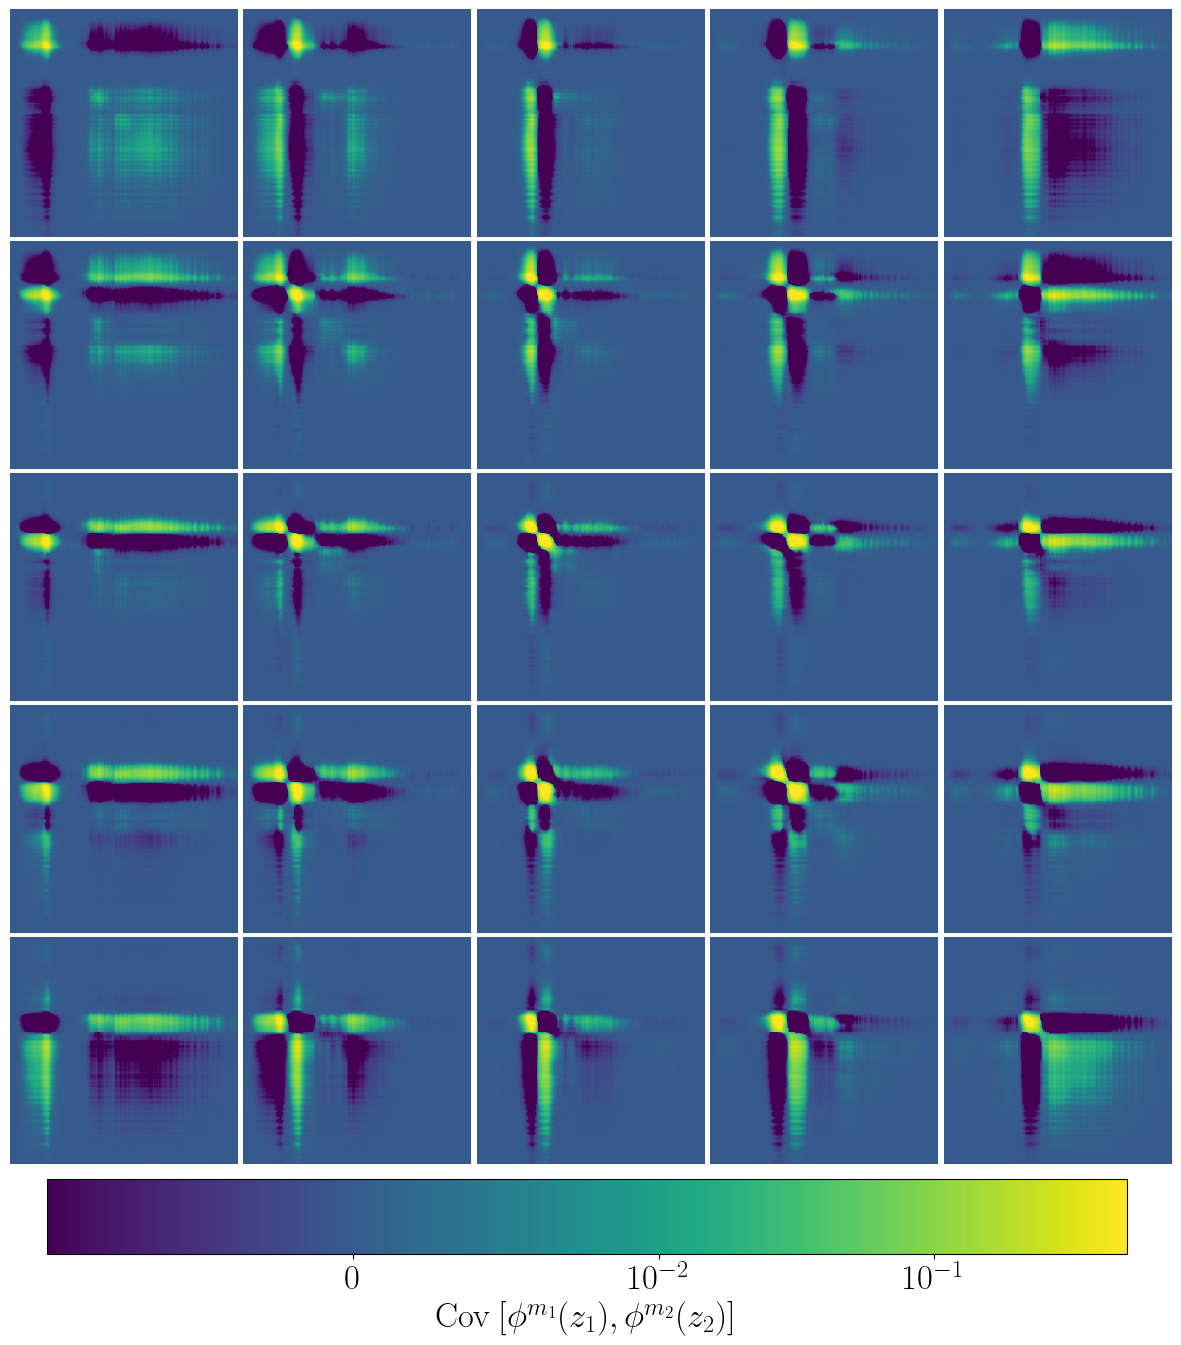

In [18]:
FIGURE, PLOT = pyplot.subplots(nrows = BIN_SIZE, ncols = BIN_SIZE, figsize = (3 * BIN_SIZE, 3 * BIN_SIZE))

INPUT_COVARIANCE = numpy.cov(TEST_INPUT.reshape(TEST_SIZE, BIN_SIZE * GRID_SIZE), rowvar = False)

for m in range(BIN_SIZE):
    
    for n in range(BIN_SIZE):
        
        NORM = colors.SymLogNorm(vmin = -0.01, vmax = +0.5, linthresh = +0.01)
        
        MAP = INPUT_COVARIANCE[n * GRID_SIZE: (n + 1) * GRID_SIZE, m * GRID_SIZE: (m + 1) * GRID_SIZE]
        
        IMAGE = PLOT[n, m].imshow(MAP, norm = NORM, cmap = 'viridis', origin = 'upper')
        
        PLOT[n, m].axis('off')
        
CAX = FIGURE.add_axes([0.15, 0.05, 0.72, 0.05])
COLORBAR = FIGURE.colorbar(cax = CAX, mappable = IMAGE, orientation = 'horizontal', label = '$\mathrm{Cov} \: [\phi^{m_1} (z_1), \phi^{m_2} (z_2)]$')

FIGURE.subplots_adjust(wspace = 0.02, hspace = 0.02)
FIGURE.savefig(PLOT_PATH + 'INPUT_COVARIANCE.pdf', bbox_inches = 'tight')

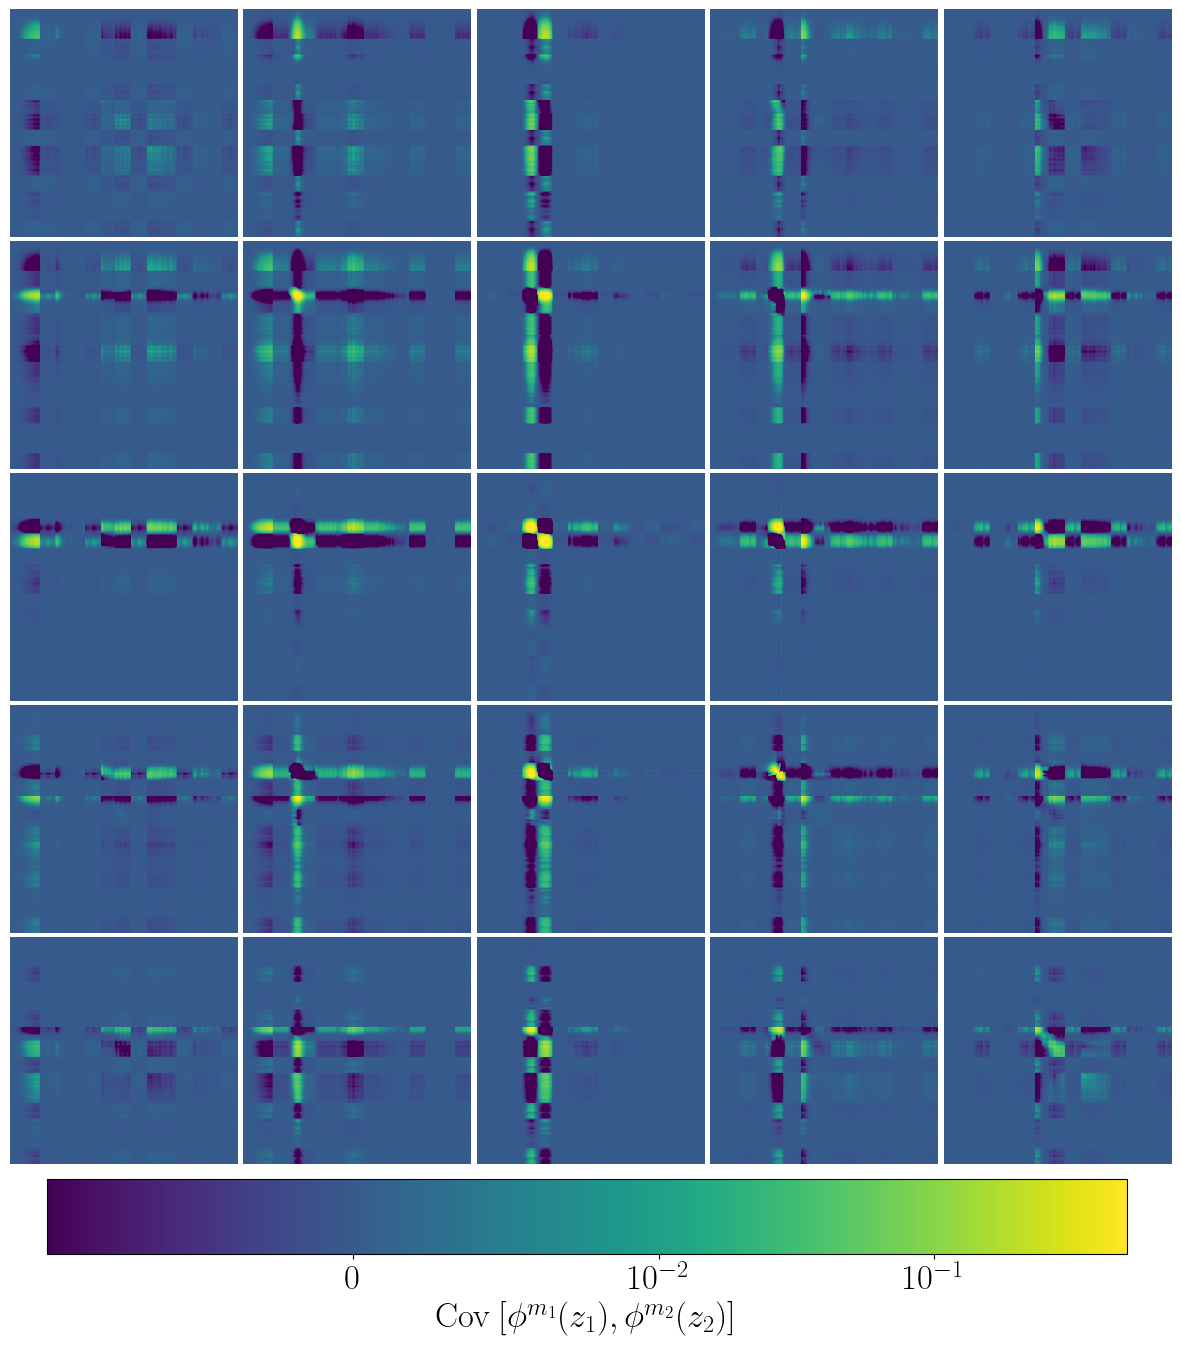

In [19]:
FIGURE, PLOT = pyplot.subplots(nrows = BIN_SIZE, ncols = BIN_SIZE, figsize = (3 * BIN_SIZE, 3 * BIN_SIZE))

OUTPUT_COVARIANCE = numpy.cov(TEST_OUTPUT.reshape(TEST_SIZE, BIN_SIZE * GRID_SIZE), rowvar = False)

for m in range(BIN_SIZE):
    
    for n in range(BIN_SIZE):
        
        NORM = colors.SymLogNorm(vmin = -0.01, vmax = +0.5, linthresh = +0.01)
        
        MAP = OUTPUT_COVARIANCE[n * GRID_SIZE: (n + 1) * GRID_SIZE, m * GRID_SIZE: (m + 1) * GRID_SIZE]
        
        IMAGE = PLOT[n, m].imshow(MAP, norm = NORM, cmap = 'viridis', origin = 'upper')
        
        PLOT[n, m].axis('off')
        
CAX = FIGURE.add_axes([0.15, 0.05, 0.72, 0.05])
COLORBAR = FIGURE.colorbar(cax = CAX, mappable = IMAGE, orientation = 'horizontal', label = '$\mathrm{Cov} \: [\phi^{m_1} (z_1), \phi^{m_2} (z_2)]$')

FIGURE.subplots_adjust(wspace = 0.02, hspace = 0.02)
FIGURE.savefig(PLOT_PATH + 'OUTPUT_COVARIANCE.pdf', bbox_inches = 'tight')